**Hantavirus Severity Prediction Using Machine Learning**

**1. Dataset Loading**

The dataset consists of clinical information relating to Hantavirus. It is a CSV file obtained from Kaggle containing 10000 rows. The main objective of the study is to predict Hantavirus severity based on some clinical features provided in the dataset. The dependent variable is the Severity column that has categories severe, critical, mild and moderate.The CSV file is being read using the Python Pandas Library. The output of 5 rows is displayed to inspect the data using the df.head() method.

In [48]:
import pandas as pd
df = pd.read_csv("hantavirus_clinical.csv")
df.head()

,patient_id,year,country,syndrome,age,sex,symptoms,incubation_days,severity,hospitalized,...,outcome,length_of_stay_days,blood_type,viral_load_category,days_to_diagnosis,treatment_protocol,geographic_setting,nationality,case_status,sequence_id
0,PT-00001,2026,MV Hondius (International),HPS,82,Male,"Hypotension, Chills, Abdominal Pain, Vomiting,...",22,Severe,1,...,Deceased,6,O+,High,2,Vasopressors + mechanical ventilation,Remote,Netherlands,Confirmed,SEQ-0001
1,PT-00002,2026,MV Hondius (International),HPS,73,Female,"Pulmonary Edema, Hypotension, Dyspnea, Cough",13,Severe,1,...,Deceased,28,A+,Low,3,ECMO + full ICU support,Remote,Netherlands,Confirmed,SEQ-0002
2,PT-00003,2026,MV Hondius (International),HPS,62,Female,"Vomiting, Chills, Hypotension, Myalgia, Tachyc...",9,Critical,1,...,Deceased,19,O+,Low,4,ECMO + full ICU support,Remote,Germany,Confirmed,SEQ-0003
3,PT-00004,2026,MV Hondius (International),HPS,82,Female,"Diarrhea, Myalgia, Nausea, Chills, Dizziness, ...",21,Critical,1,...,Recovered,22,O-,Critical,5,Vasopressors + mechanical ventilation,Remote,France,Confirmed,SEQ-0004
4,PT-00005,2026,MV Hondius (International),HPS,74,Male,"Chills, Fever, Pulmonary Edema, Myalgia",12,Severe,1,...,Recovered,14,A+,High,5,Supportive care only,Remote,USA,Confirmed,SEQ-0005


**2. Feature Engineering**

The Geographical Region was included as a predictor because different regions could impact the variations of Hantavirus Severity. The Region column has been created by mapping each country to its continental area using the already defined country column. The method df["Region"] = df["country"].map(region_map) performs this process.

In [49]:

# create a new field region for seperating each country to its region
region_map = {
    "Brazil": "South America",
    "Argentina": "South America",
    "Chile": "South America",
    "Paraguay": "South America",
    "Uruguay": "South America",
    "Colombia": "South America",
    "Bolivia": "South America",


    "USA": "North America",
    "Canada": "North America",
    "Panama": "North America",

    "Germany": "Europe",
    "Russia": "Europe",
    "Sweden": "Europe",
    "Finland": "Europe",
    "Slovenia": "Europe",
    "Croatia": "Europe",

    "China": "Asia",
    "South Korea": "Asia",

    "MV Hondius (International)": "West Africa"
}
# map country to new
df["Region"] = df["country"].map(region_map)





**3. Data Cleaning**



The Commorbidity column consisting of category None has been replaced with No Commorbidity because the None category becomes blank when the map function is run in the cell block. The method below replaces the "None" category of the Commorbidity column with "No Commorbidity". df["comorbidity"] = df["comorbidity"].replace("None", "No Comorbidity").

In [50]:
# Replace categories under comorbidity indicating None to "No Comorbidity"
df["comorbidity"] = df["comorbidity"].replace("None", "No Comorbidity")
df.head(3)


,patient_id,year,country,syndrome,age,sex,symptoms,incubation_days,severity,hospitalized,...,length_of_stay_days,blood_type,viral_load_category,days_to_diagnosis,treatment_protocol,geographic_setting,nationality,case_status,sequence_id,Region
0,PT-00001,2026,MV Hondius (International),HPS,82,Male,"Hypotension, Chills, Abdominal Pain, Vomiting,...",22,Severe,1,...,6,O+,High,2,Vasopressors + mechanical ventilation,Remote,Netherlands,Confirmed,SEQ-0001,West Africa
1,PT-00002,2026,MV Hondius (International),HPS,73,Female,"Pulmonary Edema, Hypotension, Dyspnea, Cough",13,Severe,1,...,28,A+,Low,3,ECMO + full ICU support,Remote,Netherlands,Confirmed,SEQ-0002,West Africa
2,PT-00003,2026,MV Hondius (International),HPS,62,Female,"Vomiting, Chills, Hypotension, Myalgia, Tachyc...",9,Critical,1,...,19,O+,Low,4,ECMO + full ICU support,Remote,Germany,Confirmed,SEQ-0003,West Africa


Sequence ID contains empty fields, as part of the cleaning, it will be removed because it is not relevant for the prediction task.

In [51]:
df = df.drop(columns=["sequence_id"])

**4. Data Exploration**

For data exploration, a count of the each category in Commorbidity and Country is performed using: df["comorbidity"].value_counts(dropna=False) and df["country"].value_counts(dropna = False).

The dropna=False argument allows the inclusion of missing values to the count.

In [52]:
# count the values for each category
df["comorbidity"].value_counts(dropna=False)
df["country"].value_counts(dropna = False)

,count
country,
Germany,842
Russia,832
Sweden,826
Finland,817
South Korea,804
Slovenia,792
China,786
Croatia,762
Panama,388


Further Exploration of the Dataset is performed below using df.head() to view the New Region field added and other changes in table.

In [53]:
df.head()

,patient_id,year,country,syndrome,age,sex,symptoms,incubation_days,severity,hospitalized,...,outcome,length_of_stay_days,blood_type,viral_load_category,days_to_diagnosis,treatment_protocol,geographic_setting,nationality,case_status,Region
0,PT-00001,2026,MV Hondius (International),HPS,82,Male,"Hypotension, Chills, Abdominal Pain, Vomiting,...",22,Severe,1,...,Deceased,6,O+,High,2,Vasopressors + mechanical ventilation,Remote,Netherlands,Confirmed,West Africa
1,PT-00002,2026,MV Hondius (International),HPS,73,Female,"Pulmonary Edema, Hypotension, Dyspnea, Cough",13,Severe,1,...,Deceased,28,A+,Low,3,ECMO + full ICU support,Remote,Netherlands,Confirmed,West Africa
2,PT-00003,2026,MV Hondius (International),HPS,62,Female,"Vomiting, Chills, Hypotension, Myalgia, Tachyc...",9,Critical,1,...,Deceased,19,O+,Low,4,ECMO + full ICU support,Remote,Germany,Confirmed,West Africa
3,PT-00004,2026,MV Hondius (International),HPS,82,Female,"Diarrhea, Myalgia, Nausea, Chills, Dizziness, ...",21,Critical,1,...,Recovered,22,O-,Critical,5,Vasopressors + mechanical ventilation,Remote,France,Confirmed,West Africa
4,PT-00005,2026,MV Hondius (International),HPS,74,Male,"Chills, Fever, Pulmonary Edema, Myalgia",12,Severe,1,...,Recovered,14,A+,High,5,Supportive care only,Remote,USA,Confirmed,West Africa



The code below checks for duplicates. This is important because duplicate records can cause observations to be overrepresented during training of the model, which can lead to bias of the model that can affect its performance.

df.duplicated().sum is used to inspect the dataset for duplicates.

In [54]:
# check for duplicates
duplicates = df.duplicated().sum()
print(f"Number of duplicate rows: {duplicates}")


Number of duplicate rows: 0


df.tail() is used to inspect the dataset further by viewing the last 5 rows of the dataset.

In [55]:
# print last few rows of the data

df.tail()

,patient_id,year,country,syndrome,age,sex,symptoms,incubation_days,severity,hospitalized,...,outcome,length_of_stay_days,blood_type,viral_load_category,days_to_diagnosis,treatment_protocol,geographic_setting,nationality,case_status,Region
9995,PT-09996,2010,Sweden,HFRS,27,Male,"Myalgia, Nausea, Petechiae, Oliguria, Facial F...",27,Critical,1,...,Recovered,9,O+,Critical,3,Vasopressors + mechanical ventilation,Rural,Sweden,Confirmed,Europe
9996,PT-09997,2005,Paraguay,HPS,49,Male,"Dizziness, Nausea, Diarrhea, Vomiting, Myalgia",9,Moderate,1,...,Recovered,18,O+,Low,6,IV fluids + oxygen,Rural,Paraguay,Confirmed,South America
9997,PT-09998,2026,Russia,HFRS,5,Male,"Blurred Vision, Myalgia, Facial Flushing, Head...",31,Severe,1,...,Recovered,6,O+,Critical,7,IV fluids + oxygen,Rural,Russia,Confirmed,Europe
9998,PT-09999,2021,USA,HPS,30,Female,"Hypotension, Dizziness, Fatigue, Dyspnea, Tach...",32,Severe,1,...,Recovered,3,O+,Critical,8,Vasopressors + mechanical ventilation,Remote,USA,Confirmed,North America
9999,PT-10000,2024,Finland,HFRS,12,Female,"Conjunctival Injection, Myalgia, Fever, Oligur...",34,Mild,1,...,Recovered,6,O+,Medium,11,Supportive care only,Remote,Finland,Confirmed,Europe


df.shape() illustrates the dimensions of the dataset

In [56]:
# check shape

df.shape

(10000, 26)

df.info() is used to inspect the structure and the data types of the dataset. It helps to identify null values for each column, making it easier to identify potential missing values

In [57]:
# inspect data structure

print(df.info)

<bound method DataFrame.info of      patient_id  year                     country syndrome  age     sex  \
0      PT-00001  2026  MV Hondius (International)      HPS   82    Male   
1      PT-00002  2026  MV Hondius (International)      HPS   73  Female   
2      PT-00003  2026  MV Hondius (International)      HPS   62  Female   
3      PT-00004  2026  MV Hondius (International)      HPS   82  Female   
4      PT-00005  2026  MV Hondius (International)      HPS   74    Male   
...         ...   ...                         ...      ...  ...     ...   
9995   PT-09996  2010                      Sweden     HFRS   27    Male   
9996   PT-09997  2005                    Paraguay      HPS   49    Male   
9997   PT-09998  2026                      Russia     HFRS    5    Male   
9998   PT-09999  2021                         USA      HPS   30  Female   
9999   PT-10000  2024                     Finland     HFRS   12  Female   

                                               symptoms  incubation

df.describe() is used to generate descriptive statistics such as mean, median and standard deviation for the numerical features in the dataset. df.describe() helps to provide information about the distibution and spread of data. Understanding the distribution and range of the data is important to help identify potential unusual observations, that may require further investigation.

In [58]:
# Generate descriptive Statistics of mean, median and std_dev

df.describe()


,year,age,incubation_days,hospitalized,icu_admission,mechanical_ventilation,ecmo_used,dialysis,length_of_stay_days,days_to_diagnosis
count,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
mean,2015.985200,37.539800,17.891100,0.823500,0.296200,0.081100,0.032100,0.075000,8.527900,5.573400
std,8.033706,14.713615,7.362979,0.381264,0.456603,0.273002,0.176274,0.263405,6.186893,2.842573
min,2000.000000,5.000000,7.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,2009.000000,27.000000,12.000000,1.000000,0.000000,0.000000,0.000000,0.000000,3.000000,3.000000
50%,2019.000000,38.000000,18.000000,1.000000,0.000000,0.000000,0.000000,0.000000,9.000000,5.000000
75%,2023.000000,48.000000,23.000000,1.000000,1.000000,0.000000,0.000000,0.000000,13.000000,8.000000
max,2026.000000,85.000000,46.000000,1.000000,1.000000,1.000000,1.000000,1.000000,30.000000,17.000000


df.isnull().sum() identifies number of missing values in each variable, which is important because it can affect the quality of the data. Its great practice to address it before training of the model.

In [59]:
# check for null values

df.isnull().sum()
(df.isnull().sum()/len(df))*100


,0
patient_id,0.00
year,0.00
country,0.00
syndrome,0.00
age,0.00
sex,0.00
symptoms,0.00
incubation_days,0.00
severity,0.00
hospitalized,0.00


Count the distribution of males and females to check whether data is represented evenly.
df["sex"].value_counts()

In [60]:
# explore count of male and female

df["sex"].value_counts()

,count
sex,
Male,6242
Female,3758


Count the distribution of the categories for the Severity variable with
df["severity"].value_counts()

In [61]:
# explore count of each category in severity

df['severity'].value_counts()

,count
severity,
Moderate,3319
Severe,2853
Mild,2517
Critical,1311


A correlation matrix has been performed to examine the dataset for variables that correlate with one another. This is very important because predictors that are highly correlated can provide overlapping information. In particular for models such as Logistic Regression, it can create multicollinearity and affect model interpretation.

In [62]:
# Check for correlation of variable

correlation_matrix = df.corr(numeric_only=True)

print(correlation_matrix)

                            year       age  incubation_days  hospitalized  \
year                    1.000000 -0.010804         0.010087     -0.003596   
age                    -0.010804  1.000000        -0.012432     -0.012234   
incubation_days         0.010087 -0.012432         1.000000      0.003876   
hospitalized           -0.003596 -0.012234         0.003876      1.000000   
icu_admission           0.012292 -0.004807        -0.005189      0.300337   
mechanical_ventilation  0.005335 -0.002285        -0.005805      0.137536   
ecmo_used              -0.004184  0.002881         0.000151      0.084310   
dialysis                0.011962  0.000055        -0.010639      0.131826   
length_of_stay_days    -0.008523 -0.005654        -0.000676      0.638163   
days_to_diagnosis       0.001957 -0.013011        -0.016378      0.003142   

                        icu_admission  mechanical_ventilation  ecmo_used  \
year                         0.012292                0.005335  -0.004184   


Implementation of heatmap for better visual interpretation of variables that correlate.

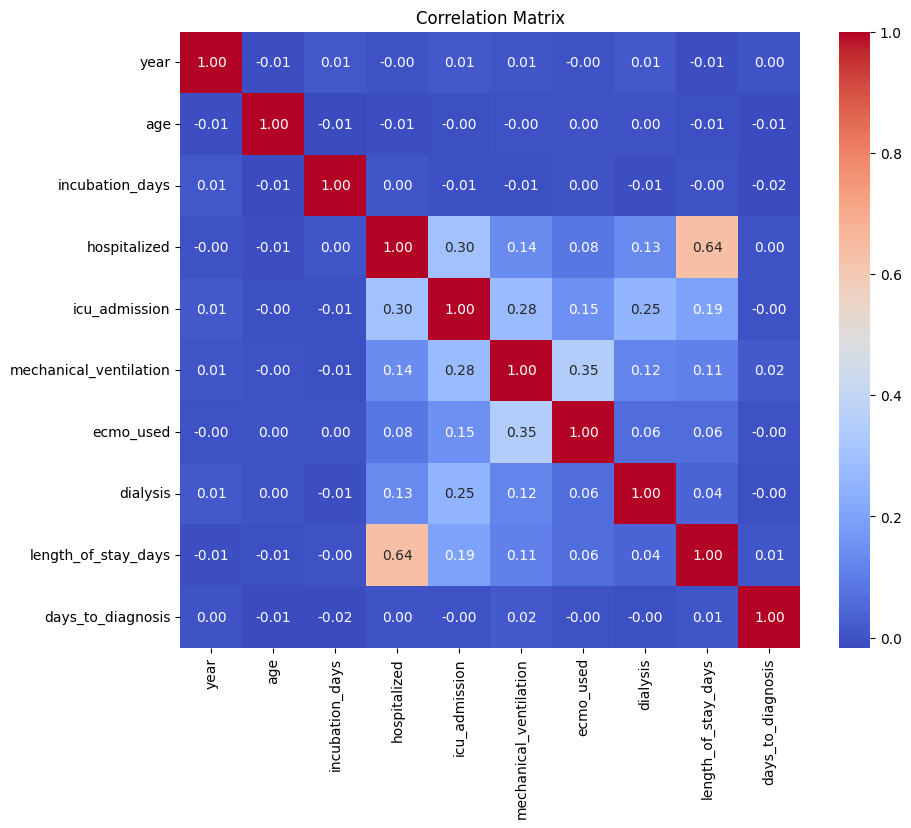

In [63]:
# Create better Visuals using Seaborn for the Variables that Correlate

import seaborn as sns
from matplotlib import pyplot as plt
plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix,
            annot=True,
            cmap='coolwarm',
            fmt='.2f')

plt.title("Correlation Matrix")
plt.show()

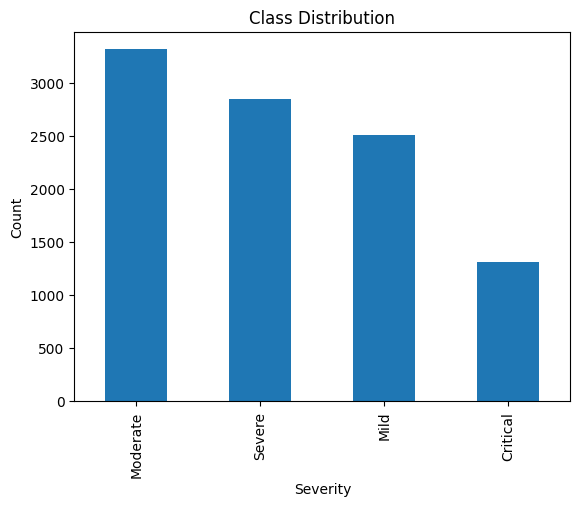

In [64]:
# Examine the percentage distribution of severity categories
df['severity'].value_counts(normalize=True) * 100

# Visualize the distribution of the Severity Class using Barchart
df['severity'].value_counts().plot(kind='bar')
plt.title('Class Distribution')
plt.xlabel('Severity')
plt.ylabel('Count')
plt.show()

Data Exploration to determine the distribution of Patients who were hospitalized and not hospitalized.

In [66]:
# check the distribution of hospitalized patients

df["hospitalized"].value_counts()

,count
hospitalized,
1,8235
0,1765


Boxplots have been created to determine potential outliers. It is important to determine unusual values because extreme observations can affect the model training. This is important because large or small proportions can influence how some models learn patterns.

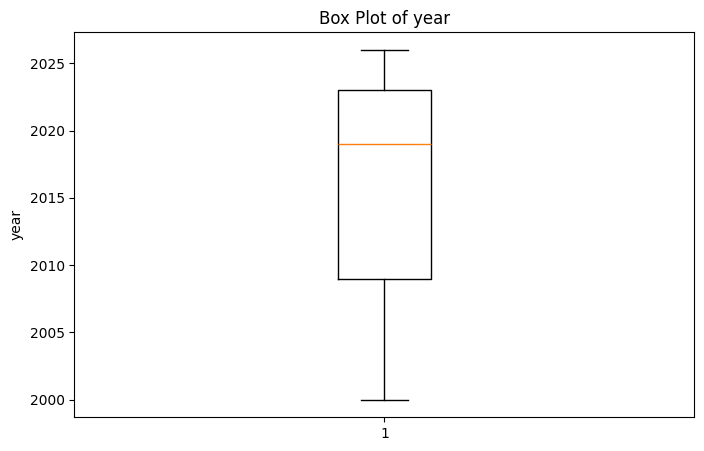

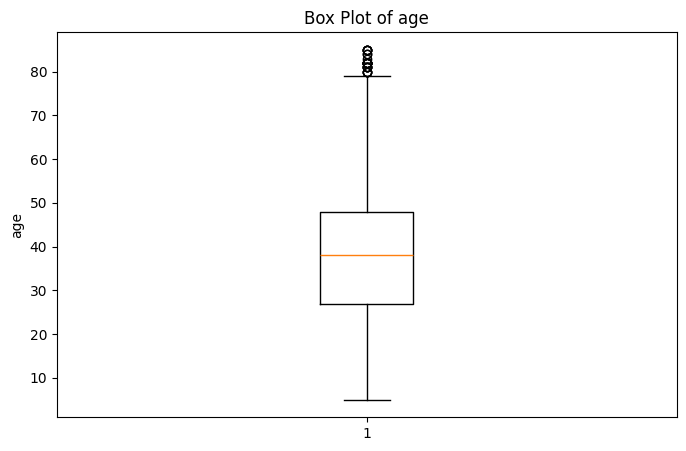

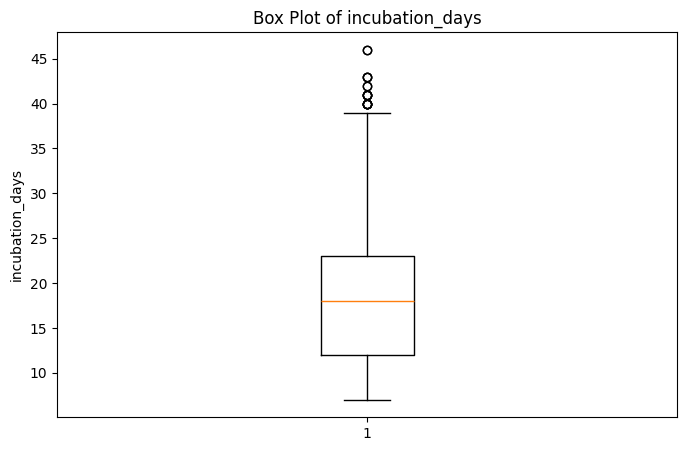

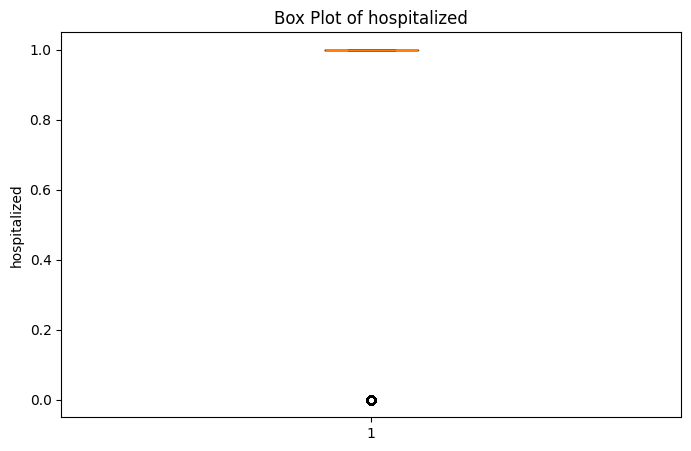

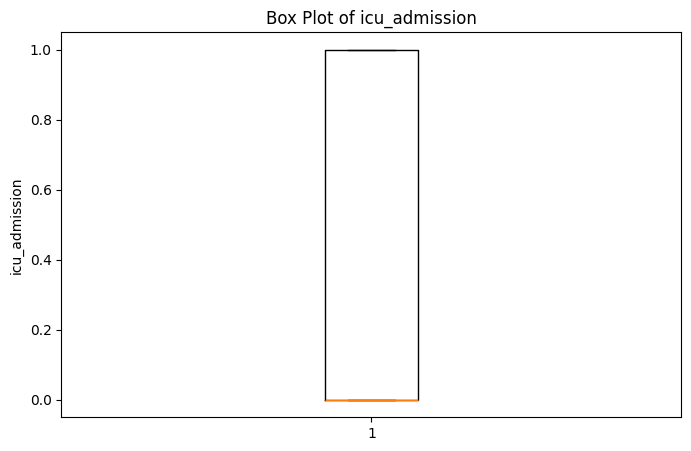

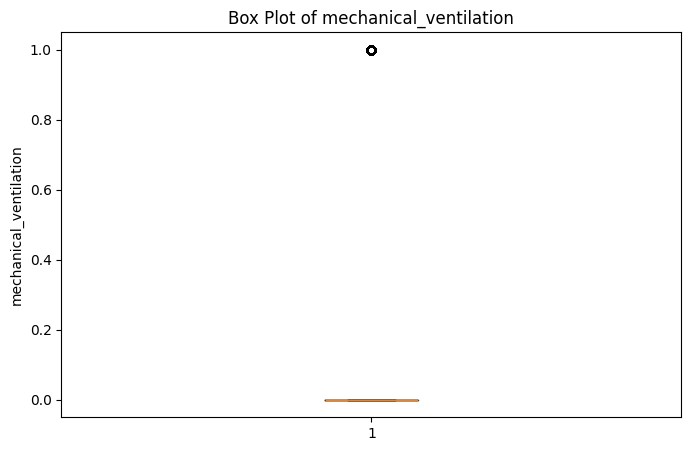

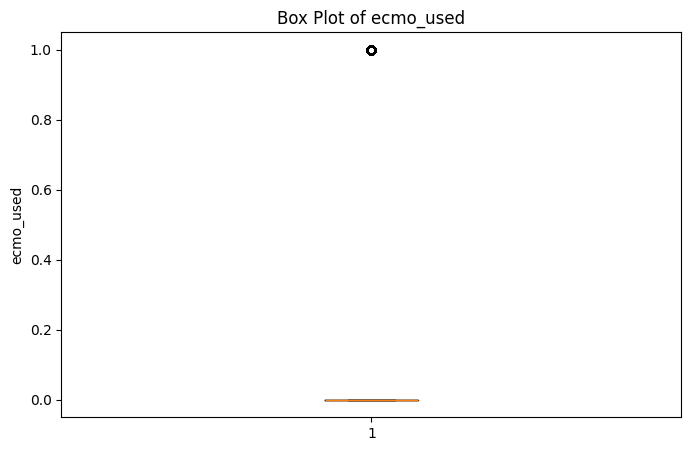

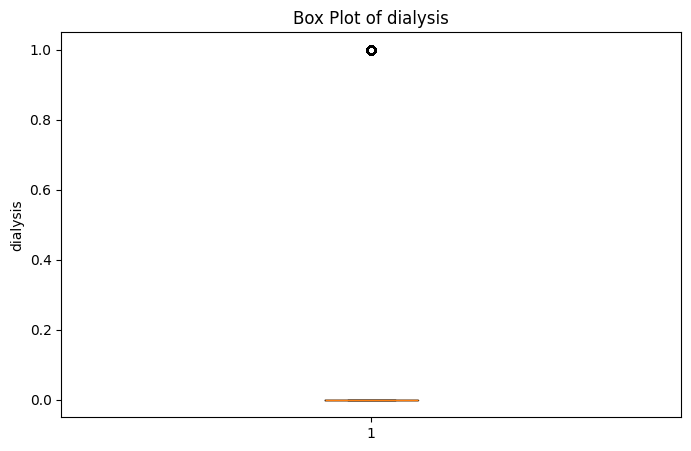

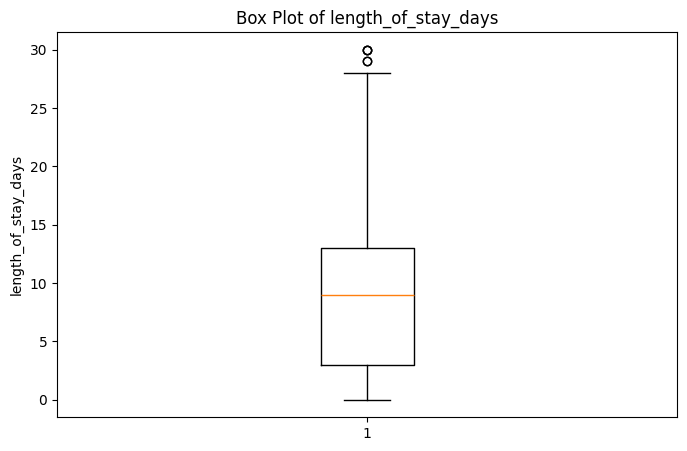

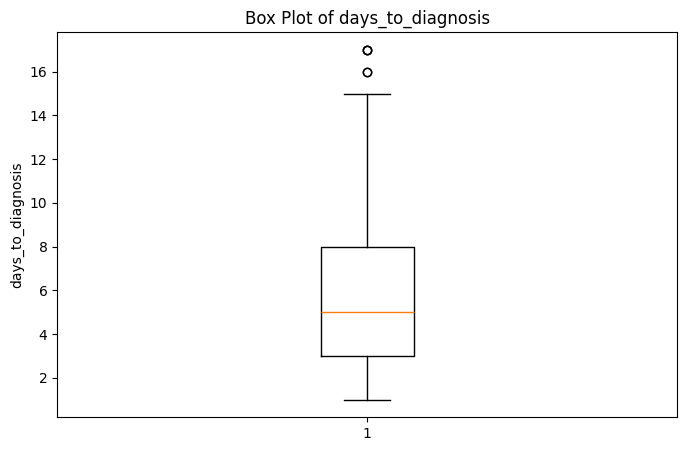

In [67]:
# Detect Potential Outliers
import matplotlib.pyplot as plt
numerical_columns = df.select_dtypes(include=['int64', 'float64']).columns

for column in numerical_columns:
    plt.figure(figsize=(8, 5))
    plt.boxplot(df[column].dropna())
    plt.title(f'Box Plot of {column}')
    plt.ylabel(column)
    plt.show()

In [68]:
# Display list of Columns

print(df.columns.to_list())

['patient_id', 'year', 'country', 'syndrome', 'age', 'sex', 'symptoms', 'incubation_days', 'severity', 'hospitalized', 'icu_admission', 'mechanical_ventilation', 'ecmo_used', 'dialysis', 'comorbidity', 'exposure_type', 'outcome', 'length_of_stay_days', 'blood_type', 'viral_load_category', 'days_to_diagnosis', 'treatment_protocol', 'geographic_setting', 'nationality', 'case_status', 'Region']


In [69]:
df.shape

(10000, 26)

One hot encoding to convert categorical variables into numerical features that can be processed by the Logistic Regression Model.

In [70]:
# encoding several categories together

categorical_features = [
    'Region',
    'blood_type',
    'syndrome',
    'sex',
    'symptoms',
    'comorbidity',
    'case_status',
    'exposure_type',
    'geographic_setting',
    'nationality',
]
df = pd.get_dummies(df, columns=categorical_features)

Explore table after One Hot Encoding

In [71]:
# View first 5 Rows after One Hot Encoding

df.head()


,patient_id,year,country,age,incubation_days,severity,hospitalized,icu_admission,mechanical_ventilation,ecmo_used,...,nationality_Netherlands,nationality_Panama,nationality_Paraguay,nationality_Russia,nationality_Slovenia,nationality_South Africa,nationality_South Korea,nationality_Sweden,nationality_USA,nationality_Uruguay
0,PT-00001,2026,MV Hondius (International),82,22,Severe,1,1,0,0,...,True,False,False,False,False,False,False,False,False,False
1,PT-00002,2026,MV Hondius (International),73,13,Severe,1,0,0,0,...,True,False,False,False,False,False,False,False,False,False
2,PT-00003,2026,MV Hondius (International),62,9,Critical,1,1,0,0,...,False,False,False,False,False,False,False,False,False,False
3,PT-00004,2026,MV Hondius (International),82,21,Critical,1,1,1,0,...,False,False,False,False,False,False,False,False,False,False
4,PT-00005,2026,MV Hondius (International),74,12,Severe,1,1,0,0,...,False,False,False,False,False,False,False,False,True,False


The data types have been checked after the performance of One Hot Encoding to verify that the cartegorical variables have been converted into machine readable numerical representations.

In [72]:
# View Data types After One Hot Encoding

df.dtypes

,0
patient_id,object
year,int64
country,object
age,int64
incubation_days,int64
...,...
nationality_South Africa,bool
nationality_South Korea,bool
nationality_Sweden,bool
nationality_USA,bool


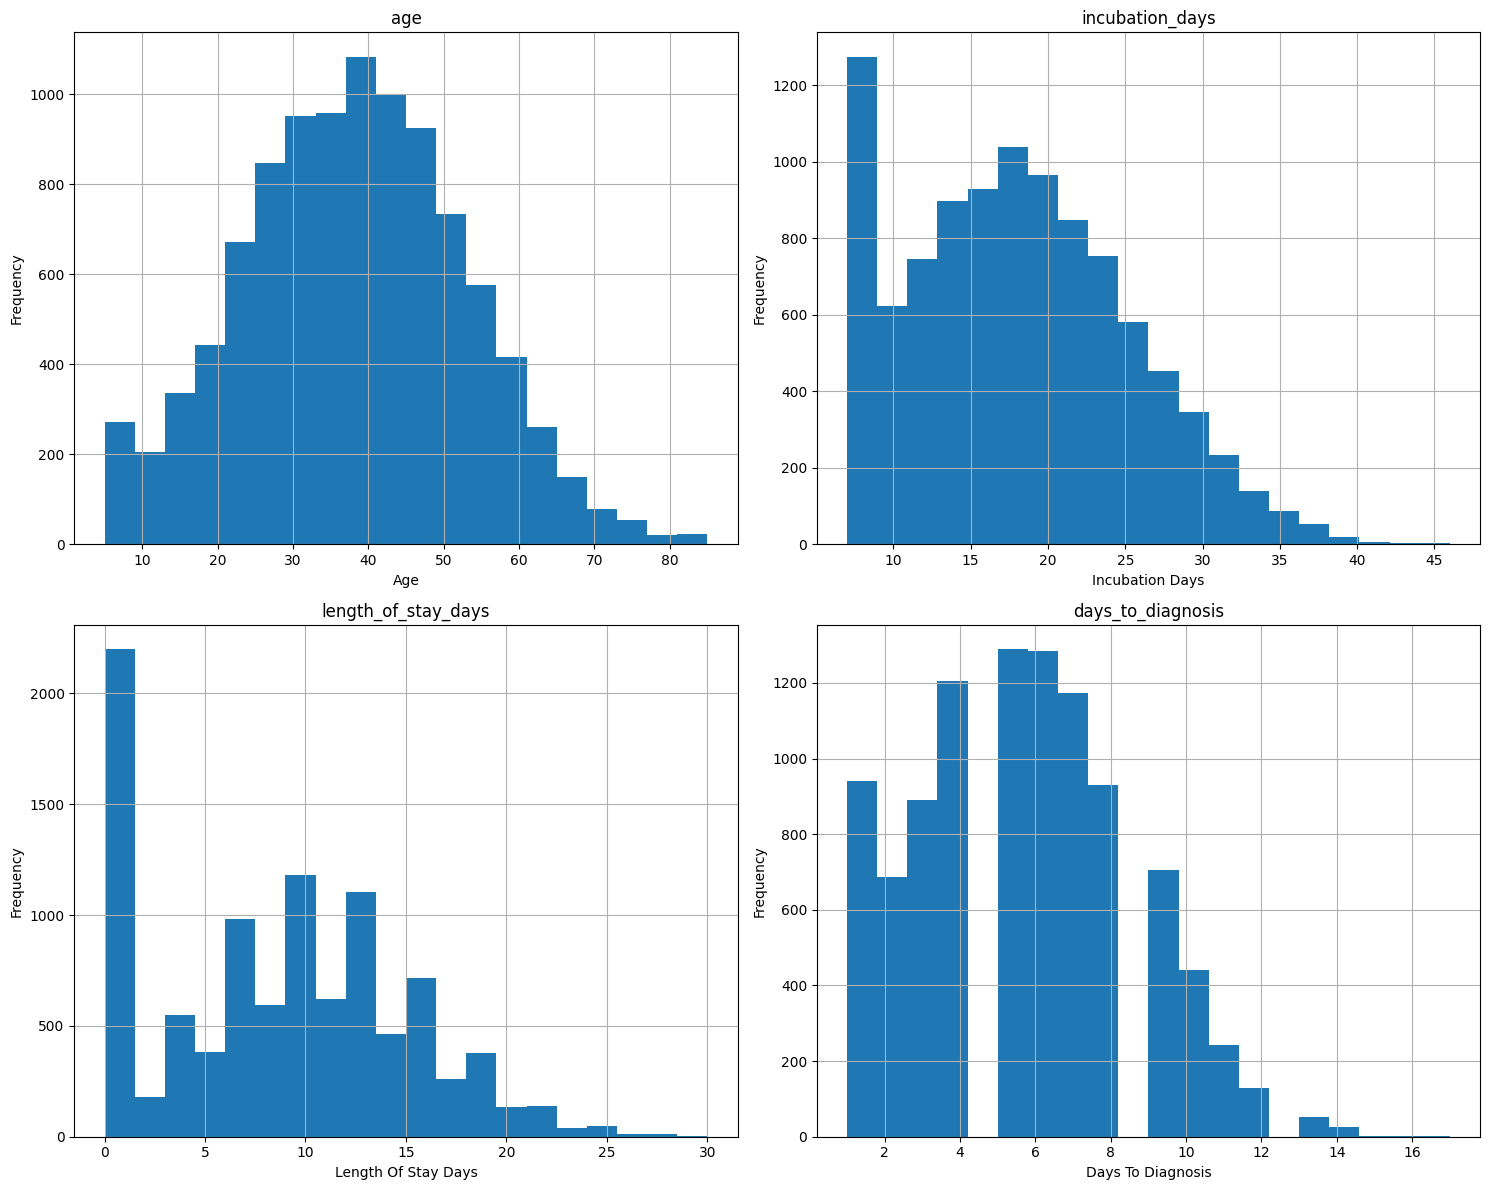

In [73]:
import matplotlib.pyplot as plt

numerical_features = df.drop(columns=['severity', 'year', 'hospitalized', 'icu_admission', 'mechanical_ventilation', 'dialysis', 'ecmo_used']).columns

axes = df[numerical_features].hist(
    figsize=(15, 12),
    bins=20
)

# Add axis labels to each histogram
for ax in axes.flatten():
    ax.set_xlabel(ax.get_title().replace('_', ' ').title())
    ax.set_ylabel('Frequency')

plt.tight_layout()
plt.show()

**4. Model Development**

Logistic Regression Without Hyperparameter Tuning**

Logistic Regression has been selected as the baseline model for the classification task used in predicting the severity of Hantavirus

The necessary Python Libraries have been imported below for data processing, model development and evaluation.

In [74]:
# Import Required Libraries

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
import xgboost as xgb
from xgboost import XGBClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)




Severity categories are encoded to numerical values allowing them to be used by the machine learning models. The categories are assigned an integer value from 0 to 3.

In [75]:

# Define the dependent or Target Variable
y = df["severity"]

severity_mapping = {
    'Mild': 0,
    'Moderate': 1,
    'Severe': 2,
    'Critical': 3
}
y_encoded = y.map(severity_mapping)

# Drop the Independent Variables and Remove Columns that are not Predictor Variables
X = df.drop(columns=["severity", "patient_id"])
X = X.drop(columns=["outcome"])
X = X.drop(columns=["treatment_protocol"])

# One Hot Encode Viral Load Category
X = pd.get_dummies(X, columns=["viral_load_category"])
X = pd.get_dummies(X, columns=["country"])

#  Split the Data into Training and Test Sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_encoded,
    test_size=0.2,
    random_state=42
)

Standardisation of Numerical Features to ensure features with different ranges are placed on comparable scale. The Scaler is only fitted to the Training Data and then it is applied to Test data to prevent data leakage

In [76]:
# Scale features
scaler = StandardScaler()

# print(X_train.select_dtypes(include=['object']).columns.tolist())
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

Logistic Regression model is trained as a baseline classification model. The scaled training data is used to train the model and the model is evaluated using the unseen test data with accuracy, confusion matrix, precision, recall, F1-score and ROC-AUC

In [77]:
# Train Logistic Model
model = LogisticRegression(random_state=42)

model.fit(X_train, y_train)

# Predictions
predictions = model.predict(X_test)

# Probabilities
probabilities = model.predict_proba(X_test)[:, 1]

# Evaluation
print("Accuracy:", accuracy_score(y_test, predictions))
print("\nConfusion Matrix")
print(confusion_matrix(y_test, predictions))

print("\nClassification Report")
print(classification_report(y_test, predictions))

# print("\nROC-AUC:", roc_auc_score(y_test, probabilities))

Accuracy: 0.727

Confusion Matrix
[[387 126  26   0]
 [ 89 507  55   4]
 [ 22  91 396  33]
 [  5  27  68 164]]

Classification Report
              precision    recall  f1-score   support

           0       0.77      0.72      0.74       539
           1       0.68      0.77      0.72       655
           2       0.73      0.73      0.73       542
           3       0.82      0.62      0.71       264

    accuracy                           0.73      2000
   macro avg       0.75      0.71      0.72      2000
weighted avg       0.73      0.73      0.73      2000



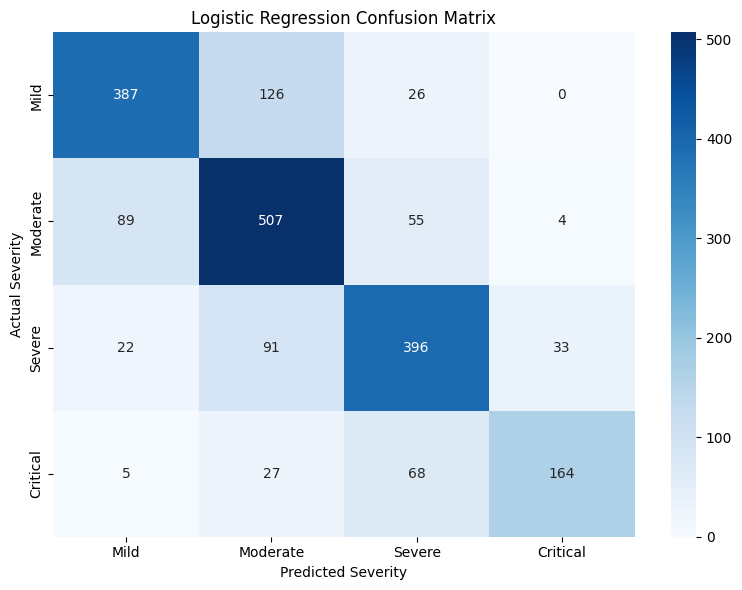

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Generate confusion matrix
cm = confusion_matrix(y_test, predictions)

# Class labels
class_names = ["Mild", "Moderate", "Severe", "Critical"]

# Plot confusion matrix
plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Severity")
plt.ylabel("Actual Severity")
plt.title("Logistic Regression Confusion Matrix")

plt.tight_layout()
plt.show()

**Random Forrest Without Hyperparameter Tuning**

Random forest is an ensemble learning algorithm which combines multiple decision trees to make a prediction for classification. It is highly useful because it is able to capture non-linear relationships between features and is also very robust when working with multiple features.

In [ ]:
rf = RandomForestClassifier(
    n_estimators=200,
    random_state=42
)

rf.fit(X_train, y_train)
# Making predictions on the test data
y_pred = rf.predict(X_test)
print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nConfusion Matrix")
print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred))

Accuracy: 0.818

Confusion Matrix
[[391 139   9   0]
 [  0 602  53   0]
 [  1  84 457   0]
 [  0  15  63 186]]
              precision    recall  f1-score   support

           0       1.00      0.73      0.84       539
           1       0.72      0.92      0.81       655
           2       0.79      0.84      0.81       542
           3       1.00      0.70      0.83       264

    accuracy                           0.82      2000
   macro avg       0.87      0.80      0.82      2000
weighted avg       0.85      0.82      0.82      2000



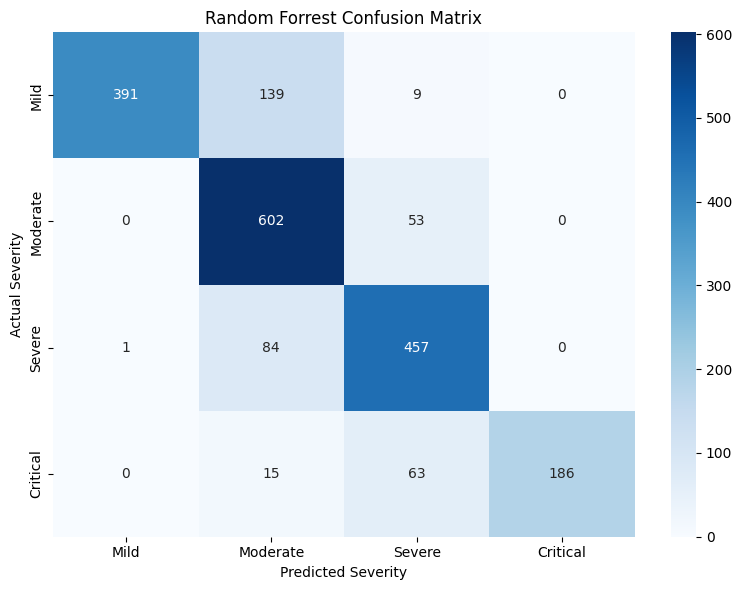

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Generate confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Class labels
class_names = ["Mild", "Moderate", "Severe", "Critical"]

# Plot confusion matrix
plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Severity")
plt.ylabel("Actual Severity")
plt.title("Random Forrest Confusion Matrix")

plt.tight_layout()
plt.show()

**XGBOOST Model Without Hyperparameter Tuning**

XGBoost is an essemble algorithm which builds decision trees sequentially, with each tree improving on the errors made by the previous tree. it is highly suitable for classification task because it can capture non-linear relationships between features and is highly effective when working with structured data.

In [78]:
model = XGBClassifier(
    objective="binary:logistic",
    n_estimators=200,
    learning_rate=0.1,
    max_depth=5,
    random_state=42,
    eval_metric="logloss"
)
X = df.copy()
# Remove all blood type features
X = X.loc[:, ~X.columns.str.startswith("blood_type_")]

model.fit(X_train, y_train) # fit the independent and dependent variable

predictions = model.predict(X_test) # make predictions for the test set

print("Accuracy:", accuracy_score(y_test, predictions))
print("\nConfusion Matrix")
print(confusion_matrix(y_test, predictions))
print(classification_report(y_test, predictions))

Accuracy: 0.8155

Confusion Matrix
[[391 145   3   0]
 [  1 623  31   0]
 [  1 108 430   3]
 [  0  15  62 187]]
              precision    recall  f1-score   support

           0       0.99      0.73      0.84       539
           1       0.70      0.95      0.81       655
           2       0.82      0.79      0.81       542
           3       0.98      0.71      0.82       264

    accuracy                           0.82      2000
   macro avg       0.87      0.79      0.82      2000
weighted avg       0.85      0.82      0.82      2000



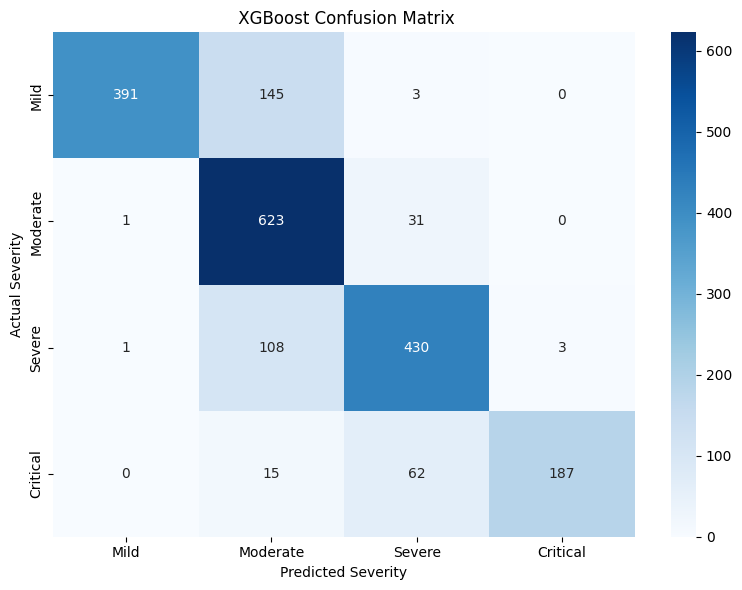

In [79]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Generate confusion matrix
cm = confusion_matrix(y_test, predictions)

# Class labels
class_names = ["Mild", "Moderate", "Severe", "Critical"]

# Plot confusion matrix
plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Severity")
plt.ylabel("Actual Severity")
plt.title(" XGBoost Confusion Matrix")

plt.tight_layout()
plt.show()

**Logistic Regression With Hyperparameter Tuning**

In [ ]:
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import LogisticRegression

# Define the Logistic Regression model
log_reg = LogisticRegression(
    solver = "liblinear",
    max_iter=2000,
    random_state=42
)

# Define hyperparameters to tune
param_grid = {
    "C": [0.01, 0.1, 1, 10, 100]
}

# Perform grid search
grid_search = GridSearchCV(
    estimator=log_reg,
    param_grid=param_grid,
    cv=5,
    scoring="accuracy"
)

# Fit the model
grid_search.fit(X_train, y_train)

# Best model
best_log_reg = grid_search.best_estimator_

# Predictions on unseen test data
y_pred = best_log_reg.predict(X_test)

print("Best Parameters:", grid_search.best_params_)
print("Accuracy:", accuracy_score(y_test, y_pred))

print("\nConfusion Matrix")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report")
print(classification_report(y_test, y_pred))

Best Parameters: {'C': 0.01}
Accuracy: 0.795

Confusion Matrix
[[391 140   6   2]
 [ 25 597  30   3]
 [  5 114 418   5]
 [  2  18  60 184]]

Classification Report
              precision    recall  f1-score   support

           0       0.92      0.73      0.81       539
           1       0.69      0.91      0.78       655
           2       0.81      0.77      0.79       542
           3       0.95      0.70      0.80       264

    accuracy                           0.80      2000
   macro avg       0.84      0.78      0.80      2000
weighted avg       0.82      0.80      0.80      2000



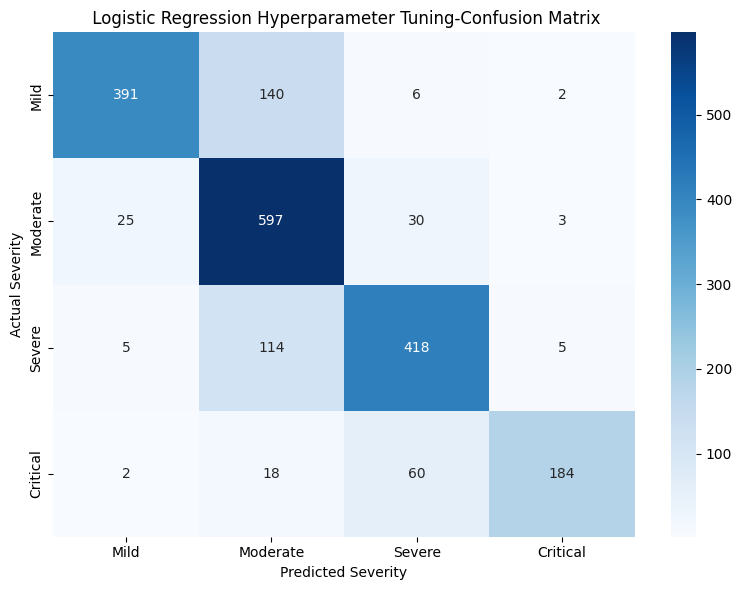

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Generate confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Class labels
class_names = ["Mild", "Moderate", "Severe", "Critical"]

# Plot confusion matrix
plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Severity")
plt.ylabel("Actual Severity")
plt.title(" Logistic Regression Hyperparameter Tuning-Confusion Matrix")

plt.tight_layout()
plt.show()

**RANDOM FORREST HYPERPARAMETER TUNING**

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV

# Define the Random Forest model
rf = RandomForestClassifier(
    random_state=42
)

# Define hyperparameters to tune
param_grid = {
    "n_estimators": [100, 200, 300],
    "max_depth": [None, 10, 20],
    "min_samples_split": [2, 5]
}

# Perform grid search
grid_search = GridSearchCV(
    estimator=rf,
    param_grid=param_grid,
    cv=5,
    scoring="accuracy",
    n_jobs=-1
)

# Fit the model
grid_search.fit(X_train, y_train)

# Best model
best_rf = grid_search.best_estimator_

# Predictions on unseen test data
y_pred = best_rf.predict(X_test)

print("Best Parameters:", grid_search.best_params_)
print("Accuracy:", accuracy_score(y_test, y_pred))

print("\nConfusion Matrix")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report")
print(classification_report(y_test, y_pred))

Best Parameters: {'max_depth': None, 'min_samples_split': 2, 'n_estimators': 300}
Accuracy: 0.8205

Confusion Matrix
[[391 142   6   0]
 [  0 603  52   0]
 [  1  81 460   0]
 [  0  12  65 187]]

Classification Report
              precision    recall  f1-score   support

           0       1.00      0.73      0.84       539
           1       0.72      0.92      0.81       655
           2       0.79      0.85      0.82       542
           3       1.00      0.71      0.83       264

    accuracy                           0.82      2000
   macro avg       0.88      0.80      0.82      2000
weighted avg       0.85      0.82      0.82      2000



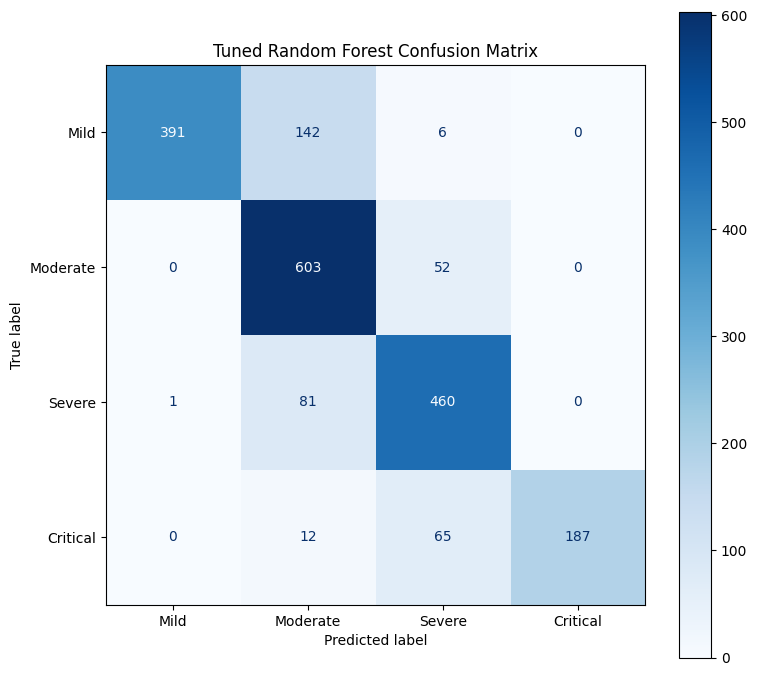

In [83]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

# Use the CORRECT confusion matrix from your small table
cm = np.array([
    [391, 142, 6, 0],
    [0, 603, 52, 0],
    [1, 81, 460, 0],
    [0, 12, 65, 187]
])

fig, ax = plt.subplots(figsize=(8, 7))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Mild", "Moderate", "Severe", "Critical"]
)

disp.plot(
    ax=ax,
    cmap="Blues",
    values_format="d"
)

ax.set_title("Tuned Random Forest Confusion Matrix")
plt.tight_layout()
plt.show()

**XGBOOST WITH HYPERPARAMETER TUNING**

In [ ]:
# Hyperparameter Tuning
from xgboost import XGBClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score, classification_report

# XGBoost model
xgb_model = XGBClassifier(
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=42
)

# Hyperparameter grid
param_grid = {
    "n_estimators": [100, 200],
    "learning_rate": [0.05, 0.1],
    "max_depth": [3, 5],
    "subsample": [0.8],
    "colsample_bytree": [0.8]
}

# Grid search
grid_search = GridSearchCV(
    estimator=xgb_model,
    param_grid=param_grid,
    cv=5,
    scoring="f1",
    n_jobs=-1,
    verbose=1
)

# Fit using training data only
grid_search.fit(X_train, y_train)

# Best parameters
print("Best Parameters:")
print(grid_search.best_params_)

# Best cross-validation score
print("Best CV F1 Score:")
print(grid_search.best_score_)

# Use the best model
best_xgb = grid_search.best_estimator_

# Test set predictions
predictions = best_xgb.predict(X_test)

# Test performance
print("Test Accuracy:", accuracy_score(y_test, predictions))
print(classification_report(y_test, predictions))

Fitting 5 folds for each of 8 candidates, totalling 40 fits


/usr/local/lib/python3.12/dist-packages/joblib/externals/loky/process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/model_selection/_search.py:1108: UserWarning: One or more of the test scores are non-finite: [nan nan nan nan nan nan nan nan]
  warnings.warn(


Best Parameters:
{'colsample_bytree': 0.8, 'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 100, 'subsample': 0.8}
Best CV F1 Score:
nan
Test Accuracy: 0.8295
              precision    recall  f1-score   support

           0       1.00      0.73      0.84       539
           1       0.70      1.00      0.82       655
           2       0.88      0.79      0.83       542
           3       1.00      0.71      0.83       264

    accuracy                           0.83      2000
   macro avg       0.89      0.80      0.83      2000
weighted avg       0.87      0.83      0.83      2000



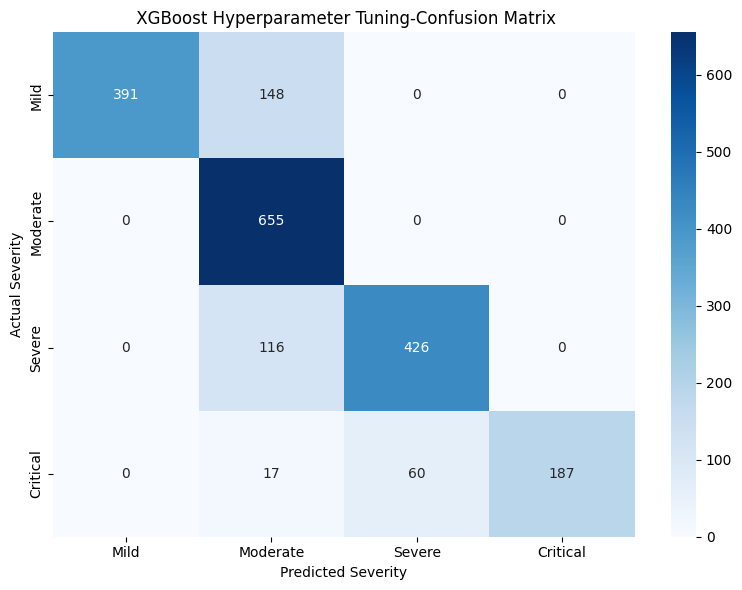

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Generate confusion matrix
cm = confusion_matrix(y_test, predictions)

# Class labels
class_names = ["Mild", "Moderate", "Severe", "Critical"]

# Plot confusion matrix
plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Severity")
plt.ylabel("Actual Severity")
plt.title(" XGBoost Hyperparameter Tuning-Confusion Matrix")

plt.tight_layout()
plt.show()

In [ ]:
print("Logistic:", 'best_log_reg' in globals())
print("Random Forest:", 'best_rf' in globals())
print("XGBoost:", 'best_xgb' in globals())

Logistic: False
Random Forest: False
XGBoost: True


**ROC-AUC CURVE**

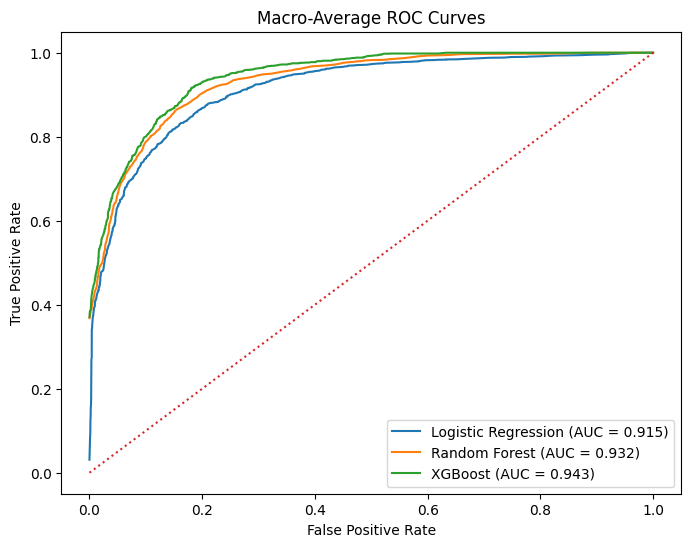


Macro-Average ROC-AUC Results
Logistic Regression: 0.915
Random Forest: 0.932
XGBoost: 0.943


In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt
import numpy as np

# --------------------------------------------------
# 1. Recreate tuned Logistic Regression
# --------------------------------------------------

best_log_reg = LogisticRegression(
    C=0.01,
    max_iter=1000
)

best_log_reg.fit(X_train, y_train)

# --------------------------------------------------
# 2. Recreate tuned Random Forest
# --------------------------------------------------

best_rf = RandomForestClassifier(
    n_estimators=300,
    max_depth=None,
    min_samples_split=2,
    random_state=42,
    n_jobs=-1
)

best_rf.fit(X_train, y_train)

# --------------------------------------------------
# 3. Get prediction probabilities
# --------------------------------------------------

y_score_lr = best_log_reg.predict_proba(X_test)
y_score_rf = best_rf.predict_proba(X_test)
y_score_xgb = best_xgb.predict_proba(X_test)

# --------------------------------------------------
# 4. Binarize the four severity classes
# --------------------------------------------------

y_test_bin = label_binarize(
    y_test,
    classes=[0, 1, 2, 3]
)

# --------------------------------------------------
# 5. Calculate macro-average ROC curves
# --------------------------------------------------

models = {
    "Logistic Regression": y_score_lr,
    "Random Forest": y_score_rf,
    "XGBoost": y_score_xgb
}

roc_results = {}

for model_name, y_score in models.items():

    fpr = {}
    tpr = {}

    for i in range(4):
        fpr[i], tpr[i], _ = roc_curve(
            y_test_bin[:, i],
            y_score[:, i]
        )

    # Common FPR points
    all_fpr = np.unique(
        np.concatenate([fpr[i] for i in range(4)])
    )

    mean_tpr = np.zeros_like(all_fpr)

    for i in range(4):
        mean_tpr += np.interp(
            all_fpr,
            fpr[i],
            tpr[i]
        )

    mean_tpr /= 4

    macro_auc = auc(all_fpr, mean_tpr)

    roc_results[model_name] = {
        "fpr": all_fpr,
        "tpr": mean_tpr,
        "auc": macro_auc
    }

# --------------------------------------------------
# 6. Plot ROC curves
# --------------------------------------------------

plt.figure(figsize=(8, 6))

for model_name, result in roc_results.items():

    plt.plot(
        result["fpr"],
        result["tpr"],
        label=f"{model_name} (AUC = {result['auc']:.3f})"
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle=":"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Macro-Average ROC Curves")
plt.legend()
plt.show()

# --------------------------------------------------
# 7. Print ROC-AUC scores
# --------------------------------------------------

print("\nMacro-Average ROC-AUC Results")

for model_name, result in roc_results.items():
    print(
        f"{model_name}: "
        f"{result['auc']:.3f}"
    )